# Anexo metodológico: candidaturas de mujeres a las alcaldías de Veracruz, 2025

Este cuaderno acompaña el análisis de las candidaturas propietarias a presidencias municipales en Veracruz. Reproduce las cifras, modelos, cuadros y gráficas del documento y compara los valores calculados con los publicados.

Los tres archivos de datos necesarios (`candidaturas_veracruz_2025.csv`, `municipios_carencias_censo2020.csv` e `integracion_2021_2025.csv`) están incluidos en este repositorio. Desde la raíz, instala `requirements.txt` y ejecuta todas las celdas en VS Code/Jupyter, o usa el comando de ejecución del README. No se requiere Colab, subir archivos ni acceso de red.

Las fuentes originales y los criterios de construcción se describen en la sección siguiente; el README reúne sus portales oficiales y la fecha de consulta.

**Contenido**

1. Fuentes y construcción de la base
2. Carga y descripción de los datos
3. Los hechos básicos: postulación, votos y cargos
4. El modelo econométrico
5. Resultados principales (cuadro A1)
6. Pruebas de robustez
7. ¿Dónde es mayor o menor la brecha? (heterogeneidad)
8. El perfil de las candidatas
9. Relevancia de las propuestas frente a las carencias del municipio
10. Dónde se postula a las mujeres
11. Análisis que quedaron fuera
12. Limitaciones
13. Trazabilidad de las cifras del documento


## 1. Fuentes y construcción de la base

La unidad de análisis es cada **candidatura propietaria a presidencia municipal** en la elección de ayuntamientos de Veracruz de 2025. La base final tiene 1,108 candidaturas en 212 municipios: 1,103 de la elección ordinaria del 1 de junio de 2025 y 5 de la elección extraordinaria de Tamiahua del 29 de marzo de 2026, que se repitió porque el tribunal anuló la ordinaria. Cada municipio tiene entre 4 y 7 candidaturas.

**Perfil de cada candidatura: Conóceles (INE).** De las fichas curriculares y de identidad se tomaron sexo, edad, escolaridad, autoadscripción indígena, redes sociales, trayectoria, propuestas, historia profesional y motivación. Con ellas se construyeron las variables del modelo:

- *Licenciatura o más* sale del último grado de estudios declarado.
- *Declaró cargo público previo* se codificó con reglas de texto sobre la trayectoria: cuenta si menciona un puesto de funcionario (dirección, jefatura, tesorería, etc.), de cabildo o agencia municipal, o de alcaldía, diputación o alto nivel.
- *Ficha con texto repetido* vale 1 si la trayectoria, las propuestas, la historia profesional o la motivación tienen una similitud de 0.8 o más con la ficha de otra candidatura. La similitud es el coseno entre vectores TF-IDF de palabras. Todas las coincidencias encontradas son con fichas del mismo partido, lo que sugiere formatos llenados por el partido.
- *Redes propias* cuenta Facebook, X, Instagram, YouTube, TikTok, otra red y sitio web. Excluye los enlaces del partido y las URL que se repiten en tres o más candidaturas, que son institucionales.
- *Temas de las propuestas* son once indicadores por palabras clave: seguridad, agua y drenaje, vialidades y obra, salud, educación, economía y empleo, campo, transparencia, grupos vulnerables, medio ambiente, y cultura y deporte.

**Votos: cómputo oficial del SICEE (INE-OPLE), 2021 y 2025.** El voto de cada candidatura se construyó con el archivo por partido (`MUN`), no con el archivo por candidatura (`MUNCAND`). El OPLE reportó un error de llenado en `MUNCAND` para Tlacotalpan (oficio OPLEV/DEOE/0587/2026), y Ayahualulco se corrigió después solo en los archivos municipales (oficio 0677/2026). El SICEE numera a las candidaturas independientes a nivel estatal, así que se asignaron municipio por municipio. Para Tamiahua se usó el PREP de la elección extraordinaria (100 por ciento de actas).

**Cargos electos: integración oficial de ayuntamientos y del Congreso, 2021 y 2025.** Trae sexo de presidencias, sindicaturas, regidurías y diputaciones. El ganador por votos coincide con la integración en los 211 municipios ordinarios.

**Antecedentes políticos: cruces con la elección de 2021.**

- *Votación del partido en 2021* es el porcentaje que obtuvo cada partido en el municipio. Los votos por combinación de coalición se repartieron en partes iguales.
- *El partido gobernaba* vale 1 si ganó la presidencia en 2021.
- *Cargo 2022-2025* vale 1 si el nombre de la candidatura aparece como síndica(o), regidor(a) o diputada(o) local electo en 2021.
- *Apellido compartido* vale 1 si comparte al menos un apellido con quien ganó la presidencia de su municipio en 2021. Como placebo se compara también con el alcalde de un municipio elegido al azar.

**Población y carencias: Censo 2020 (INEGI).** Vienen de la base seccional. Se agregaron por municipio sumando numeradores y denominadores de todas sus secciones, en lugar de promediar porcentajes.

Los archivos que usa este cuaderno ya contienen estas variables. No incluyen nombres de personas.

In [1]:
import warnings
from pathlib import Path
import matplotlib.patheffects as pe
from matplotlib.text import Text
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

ARCHIVOS = ['candidaturas_veracruz_2025.csv', 'municipios_carencias_censo2020.csv', 'integracion_2021_2025.csv']
REPO_ROOT = Path.cwd()
if not all((REPO_ROOT / archivo).is_file() for archivo in ARCHIVOS):
    REPO_ROOT = REPO_ROOT.parent
faltantes = [archivo for archivo in ARCHIVOS if not (REPO_ROOT / archivo).is_file()]
if faltantes:
    raise FileNotFoundError("Faltan archivos del repositorio: " + ", ".join(faltantes))

cand = pd.read_csv(REPO_ROOT / ARCHIVOS[0])
mun = pd.read_csv(REPO_ROOT / ARCHIVOS[1], index_col='ID_MUNICIPIO')
integ = pd.read_csv(REPO_ROOT / ARCHIVOS[2])

# variables derivadas
cand['edad_dec'] = cand.edad / 10
cand['log_len_total'] = np.log1p(cand.len_total)


## 2. Carga y descripción de los datos

La base de candidaturas tiene una fila por candidatura. Las variables principales son:

| Variable | Qué mide |
|---|---|
| `share100` | Porcentaje de la votación válida del municipio que obtuvo la candidatura (0 a 100). Es la variable dependiente principal. |
| `votos_ln` | Votos de la candidatura por cada cien personas en la lista nominal. |
| `gano` | 1 si ganó la presidencia municipal. |
| `mujer` | 1 si la propietaria es mujer. |
| `edad_dec`, `lic_o_mas`, `tray_cargo_previo`, `plantilla_alguno`, `fb_personal`, `n_redes_personal`, `log_len_total`, `indigena` | Perfil de la ficha de Conóceles. |
| `fuerza21`, `partido_gobierna`, `cargo_2021_oficial`, `apellido_alcalde21` | Antecedentes políticos. |
| `tema_*` | Temas mencionados en las propuestas. |
| `pob2020` | Población del municipio (Censo 2020). |

In [2]:
print('Candidaturas por partido o coalición:')
print(cand.partido.value_counts().rename({'MOR_PVEM': 'Morena-PVEM (coalición)', 'MOR': 'Morena sola', 'PVEM': 'PVEM solo', 'CI': 'Independientes'}).to_string())
print('\nCandidaturas por elección:'); print(cand.eleccion.value_counts().to_string())
print('\nCandidaturas por municipio:', cand.groupby('ID_MUNICIPIO').size().describe()[['min', 'mean', 'max']].round(1).to_dict())
cand[['share100', 'votos_ln', 'gano', 'mujer', 'edad', 'lic_o_mas', 'tray_cargo_previo', 'plantilla_alguno', 'n_redes_personal', 'indigena', 'fuerza21', 'pob2020']].describe().T.round(2)

Candidaturas por partido o coalición:
partido
PAN                        212
PT                         211
MC                         211
PRI                        207
Morena-PVEM (coalición)    166
Morena sola                 45
PVEM solo                   41
Independientes              15

Candidaturas por elección:
eleccion
ordinaria 2025         1103
extraordinaria 2026       5

Candidaturas por municipio: {'min': 4.0, 'mean': 5.2, 'max': 7.0}


,count,mean,std,min,25%,50%,75%,max
share100,1108.0,19.10,18.16,0.0,2.07,13.84,32.74,97.50
votos_ln,1108.0,11.98,11.90,0.0,1.13,8.10,20.41,54.06
gano,1108.0,0.19,0.39,0.0,0.00,0.00,0.00,1.00
mujer,1108.0,0.50,0.50,0.0,0.00,0.50,1.00,1.00
edad,1108.0,46.67,10.83,19.0,39.00,47.00,54.00,79.00
lic_o_mas,1108.0,0.63,0.48,0.0,0.00,1.00,1.00,1.00
tray_cargo_previo,1108.0,0.38,0.49,0.0,0.00,0.00,1.00,1.00
plantilla_alguno,1108.0,0.08,0.27,0.0,0.00,0.00,0.00,1.00
n_redes_personal,1108.0,0.63,1.01,0.0,0.00,0.00,1.00,7.00
indigena,1108.0,0.25,0.43,0.0,0.00,0.00,0.00,1.00


## 3. Los hechos básicos: postulación, votos y cargos

Esta sección reproduce las cifras de la primera parte del documento y la gráfica 1A.

Las mujeres fueron la mitad de las candidaturas, pero recibieron 30 por ciento de los votos y ganaron una de cada cuatro presidencias, igual que en 2021.

En el resto del cabildo la proporción se invierte. Dos reglas lo explican:

- **Sindicaturas.** El artículo 16 del Código Electoral de Veracruz obliga a que la presidencia y la sindicatura de cada planilla sean de sexos distintos. Por eso cada presidencia que gana un hombre lleva consigo una síndica.
- **Regidurías.** Se reparten por listas de cada partido. Para 2025 el OPLE dispuso que las listas empezaran con el sexo contrario al de 2021 y que, donde hay una sola regiduría, fuera para una mujer.

In [3]:
pct_cand = 100 * cand.mujer.mean()
pct_votos = 100 * cand.loc[cand.mujer == 1, 'votos'].sum() / cand.votos.sum()
ganadoras = cand[cand.gano == 1]
n_alc, n_mun = int(ganadoras.mujer.sum()), cand.ID_MUNICIPIO.nunique()

def pct_mujeres(anio, cargo, lista=None):
    d = integ[(integ.anio == anio) & (integ.cargo == cargo)]
    if lista is not None: d = d[d.numero_lista == lista]
    return 100 * d.mujer.mean(), int(d.mujer.notna().sum())

sind25, _ = pct_mujeres(2025, 'SIND_MR'); reg25, _ = pct_mujeres(2025, 'REG_RP')
pres21, n21 = pct_mujeres(2021, 'PRES_MUN'); reg21, _ = pct_mujeres(2021, 'REG_RP')
dip21, _ = pct_mujeres(2021, 'DIP_LOC_MR')
print(f'Candidaturas de mujeres: {pct_cand:.1f}%   |   votos para mujeres: {pct_votos:.1f}%')
print(f'Alcaldesas 2025: {n_alc} de {n_mun} ({100*n_alc/n_mun:.1f}%)   |   2021: {pres21:.1f}% de {n21} con sexo registrado')
print(f'Sindicaturas 2025: {sind25:.1f}%   |   regidurías: {reg21:.1f}% (2021) -> {reg25:.1f}% (2025)')
print(f'Diputaciones locales de mayoría relativa 2021: {dip21:.0f}% (2024: 16 de 30, dato de prensa, no está en esta base)')

# presidencia y sindicatura de sexo distinto
pres_m = integ[(integ.anio == 2025) & (integ.cargo == 'PRES_MUN')].set_index('ID_MUNICIPIO').mujer
sind_m = integ[(integ.anio == 2025) & (integ.cargo == 'SIND_MR')].set_index('ID_MUNICIPIO').mujer
n_sind_distinto = int((pres_m != sind_m).sum())
print(f'Sindicatura de sexo distinto a la presidencia: {n_sind_distinto} de {len(pres_m)} ayuntamientos')

# regidurías: primer lugar de lista y ayuntamientos con una sola regiduría
r1_21, _ = pct_mujeres(2021, 'REG_RP', 1); r1_25, _ = pct_mujeres(2025, 'REG_RP', 1)
reg = integ[integ.cargo == 'REG_RP'].copy()
reg['n_reg'] = reg.groupby(['anio', 'ID_MUNICIPIO']).mujer.transform('size')
una = reg[reg.n_reg == 1].groupby('anio').agg(municipios=('ID_MUNICIPIO', 'nunique'), mujeres=('mujer', 'mean'))
print(f'Primer lugar de las listas de regidurías: {r1_21:.0f}% (2021) -> {r1_25:.0f}% (2025)')
print('Ayuntamientos con una sola regiduría:'); print(una.assign(mujeres=lambda x: (100*x.mujeres).round(0)).to_string())

# votación promedio y concentración de derrotas
print(f"\nVotación promedio: mujeres {cand[cand.mujer==1].share100.mean():.1f}%, hombres {cand[cand.mujer==0].share100.mean():.1f}%")
g20 = cand.assign(m20=(cand.share100 > 20) & (cand.mujer == 1)).groupby('ID_MUNICIPIO').m20.any()
print(f'Municipios donde ninguna candidata superó 20% de los votos: {(~g20).sum()} de {len(g20)}')

Candidaturas de mujeres: 50.0%   |   votos para mujeres: 30.5%
Alcaldesas 2025: 54 de 212 (25.5%)   |   2021: 24.0% de 208 con sexo registrado
Sindicaturas 2025: 76.3%   |   regidurías: 45.7% (2021) -> 71.7% (2025)
Diputaciones locales de mayoría relativa 2021: 40% (2024: 16 de 30, dato de prensa, no está en esta base)
Sindicatura de sexo distinto a la presidencia: 208 de 211 ayuntamientos
Primer lugar de las listas de regidurías: 43% (2021) -> 91% (2025)
Ayuntamientos con una sola regiduría:
      municipios  mujeres
anio                     
2021         105     35.0
2025         105     92.0

Votación promedio: mujeres 12.2%, hombres 26.0%
Municipios donde ninguna candidata superó 20% de los votos: 103 de 212


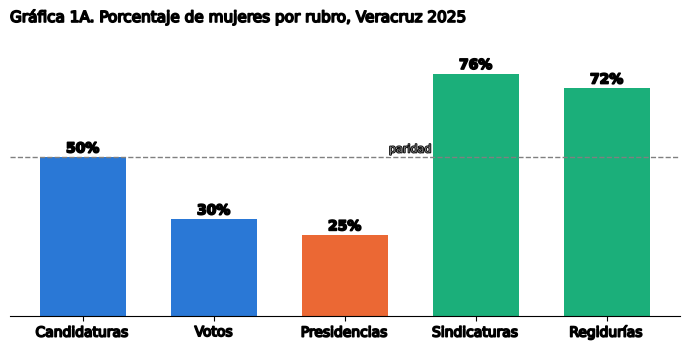

In [4]:
from pathlib import Path
AZUL, NARANJA, VERDE, GRIS = '#2A78D6', '#EB6834', '#1BAF7A', '#808080'
def r0(v): return f'{np.floor(v + 0.5):.0f}'   # redondeo convencional (18.5 -> 19)
fig, ax = plt.subplots(figsize=(7, 3.6))
etq = ['Candidaturas', 'Votos', 'Presidencias', 'Sindicaturas', 'Regidurías']
val = [pct_cand, pct_votos, 100*n_alc/n_mun, sind25, reg25]
barras = ax.bar(etq, val, color=[AZUL, AZUL, NARANJA, VERDE, VERDE], width=0.65)
ax.axhline(50, color=GRIS, ls='--', lw=1); ax.text(2.5, 51.5, 'paridad', color=GRIS, fontsize=8, ha='center')
for b, v in zip(barras, val): ax.text(b.get_x()+b.get_width()/2, v+1.5, r0(v) + '%', ha='center', fontsize=10, fontweight='bold')
ax.set_ylim(0, 90); ax.set_yticks([]); [ax.spines[k].set_visible(False) for k in ['top', 'right', 'left']]
ax.set_title('Gráfica 1A. Porcentaje de mujeres por rubro, Veracruz 2025', loc='left', fontsize=11)
plt.tight_layout()
fig.patch.set_alpha(0)
for ax in fig.axes:
    ax.patch.set_alpha(0)
for texto in fig.findobj(match=Text):
    texto.set_path_effects([pe.Stroke(linewidth=3.2, foreground='white'),
                            pe.Stroke(linewidth=1.2, foreground='black'), pe.Normal()])
figuras_dir = Path('docs/figuras') if Path('docs').is_dir() else Path('../docs/figuras')
figuras_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figuras_dir / 'grafica_1A_participacion.png', dpi=150, transparent=True, facecolor='none', edgecolor='none', bbox_inches='tight')
plt.show()

## 4. El modelo econométrico

### Qué se quiere medir

La pregunta es cuántos votos menos obtiene una candidata que un candidato. Comparar promedios simples no basta: las mujeres podrían concentrarse en municipios o partidos donde a cualquiera le iría mal. Por eso el modelo compara cada candidatura solo con sus rivales de la misma boleta y descuenta el peso habitual de cada partido.

### Especificación

Se estima una regresión lineal por mínimos cuadrados ordinarios (MCO):

$$
V_{ipm} = \beta\,\text{Mujer}_{ipm} + X_{ipm}'\delta + \alpha_m + \gamma_p + \varepsilon_{ipm}
$$

donde $V_{ipm}$ es el porcentaje de votos de la candidatura $i$ del partido $p$ en el municipio $m$; $\text{Mujer}$ vale 1 si la candidata es mujer; $X$ son rasgos de perfil y antecedentes; $\alpha_m$ es un **efecto fijo de municipio** y $\gamma_p$ un **efecto fijo de partido**. El coeficiente de interés es $\beta$, la diferencia promedio de votación entre una candidata y un candidato.

**Efecto fijo de municipio.** Es una constante propia de cada municipio. Con ella, $\beta$ se estima solo comparando candidaturas de la misma boleta, y todo lo que comparten queda descontado: tamaño, marginación, participación, gobierno saliente, clima político local. Si las mujeres perdieran solo porque se les postula en municipios difíciles, $\beta$ se acercaría a cero al incluirlo. Ocurre lo contrario.

**Efecto fijo de partido.** Descuenta la votación promedio de cada partido en el estado, para que la brecha no refleje que las candidatas se concentren en partidos pequeños. En cada municipio cada partido tiene una sola candidatura: se compara, por ejemplo, a una candidata del PRI con lo que suele obtener el PRI.

**Perfil equivalente.** Al añadir $X$, $\beta$ compara a una candidata con un candidato de la misma elección que tienen los mismos valores en todos esos rasgos. Es un ajuste estadístico promedio, no un emparejamiento de personas idénticas.

**Errores estándar agrupados por municipio.** Dentro de un municipio los porcentajes de todas las candidaturas suman cien, así que sus errores no son independientes. Agruparlos permite cualquier correlación entre candidaturas de un mismo municipio.

**Desenlaces alternativos.** Como los porcentajes suman cien, lo que gana una candidatura lo pierde otra por construcción. Para descartar que eso produzca la brecha, el modelo se repite con dos variables sin esa restricción: los votos por cada cien personas en la lista nominal, y ganar o no (un modelo lineal de probabilidad, cuyos coeficientes se leen como cambios en la probabilidad de ganar).

La función siguiente estima todos los modelos del cuaderno con esta especificación.

In [5]:
def mco(formula, y='share100', datos=None, ef_municipio=True, ef_partido=True):
    """MCO con efectos fijos de municipio y partido y errores agrupados por municipio."""
    d = cand if datos is None else datos
    usadas = [v for v in d.columns if v in formula.replace('*', ' ').replace(':', ' ').replace('+', ' ').split() or v == y]
    d = d.dropna(subset=usadas)
    ef = (' + C(ID_MUNICIPIO)' if ef_municipio else '') + (' + C(partido)' if ef_partido else '')
    return smf.ols(f'{y} ~ {formula}{ef}', d).fit(cov_type='cluster', cov_kwds={'groups': d.ID_MUNICIPIO})

def efecto(m, v='mujer'):
    lo, hi = m.conf_int().loc[v]
    return pd.Series({'coef': m.params[v], 'ee': m.bse[v], 'p': m.pvalues[v], 'ic_inf': lo, 'ic_sup': hi, 'N': int(m.nobs)})

PERFIL = 'edad_dec + lic_o_mas + tray_cargo_previo + plantilla_alguno + fb_personal + n_redes_personal + log_len_total + indigena'
ANTECEDENTES = 'fuerza21 + partido_gobierna + cargo_2021_oficial + apellido_alcalde21'

## 5. Resultados principales (cuadro A1)

El cuadro agrega explicaciones de izquierda a derecha. La primera fila es la clave:

- **Sin controles:** la diferencia entre candidatas y candidatos es de 14 puntos.
- **Misma elección y mismo partido:** crece a 18 puntos.
- **Más el perfil de Conóceles:** baja apenas a 17.
- **Más los antecedentes políticos:** baja a 16.

Todo lo que se puede medir de las candidaturas explica menos de 2 de los 18 puntos. La última columna repite el modelo completo con ganar como variable dependiente: las candidatas tienen 22 puntos porcentuales menos de probabilidad de ganar.

In [6]:
M = {'Sin controles': mco('mujer', ef_municipio=False, ef_partido=False),
     'Misma elección y partido': mco('mujer'),
     '+ perfil Conóceles': mco('mujer + ' + PERFIL),
     '+ antecedentes políticos': mco('mujer + ' + PERFIL + ' + ' + ANTECEDENTES),
     'Probabilidad de ganar': mco('mujer + ' + PERFIL + ' + ' + ANTECEDENTES, y='gano')}
ETIQ = {'mujer': 'Candidatura de mujer', 'edad_dec': 'Edad (por década)', 'lic_o_mas': 'Licenciatura o más',
        'tray_cargo_previo': 'Declaró cargo público previo', 'plantilla_alguno': 'Ficha con texto repetido',
        'fb_personal': 'Cuenta propia de Facebook', 'n_redes_personal': 'Número de redes propias',
        'log_len_total': 'Extensión de la ficha (log)', 'indigena': 'Autoadscripción indígena',
        'fuerza21': 'Votación del partido en 2021 (puntos)', 'partido_gobierna': 'El partido gobernaba el municipio',
        'cargo_2021_oficial': 'Cargo en 2022-2025 (síndico, regidor, diputado)', 'apellido_alcalde21': 'Comparte apellido con el alcalde saliente'}
def estrellas(p): return '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.1 else ''
filas = {}
for v, e in ETIQ.items():
    filas[e] = [f"{m.params[v]:.3f}{estrellas(m.pvalues[v])} ({m.bse[v]:.3f})" if k == 'Probabilidad de ganar' else
                f"{m.params[v]:.2f}{estrellas(m.pvalues[v])} ({m.bse[v]:.2f})" if v in m.params else '' for k, m in M.items()]
filas['Efectos fijos de municipio y partido'] = ['No', 'Sí', 'Sí', 'Sí', 'Sí']
filas['Observaciones'] = [f'{int(m.nobs):,}' for m in M.values()]
filas['R²'] = [f'{m.rsquared:.2f}' for m in M.values()]
cuadro_a1 = pd.DataFrame(filas, index=M.keys()).T
print('Cuadro A1. Determinantes del voto de cada candidatura. Coeficiente (error estándar agrupado por municipio). *** p<0.01, ** p<0.05, * p<0.1')
cuadro_a1

Cuadro A1. Determinantes del voto de cada candidatura. Coeficiente (error estándar agrupado por municipio). *** p<0.01, ** p<0.05, * p<0.1


,Sin controles,Misma elección y partido,+ perfil Conóceles,+ antecedentes políticos,Probabilidad de ganar
Candidatura de mujer,-13.76*** (1.05),-17.97*** (1.22),-16.98*** (1.26),-16.16*** (1.21),-0.222*** (0.029)
Edad (por década),,,-0.01 (0.58),0.03 (0.54),0.005 (0.014)
Licenciatura o más,,,1.86 (1.30),2.01* (1.19),-0.013 (0.033)
Declaró cargo público previo,,,3.59*** (1.29),2.98** (1.28),0.006 (0.037)
Ficha con texto repetido,,,-5.63*** (1.89),-4.57** (1.79),-0.100** (0.042)
Cuenta propia de Facebook,,,0.72 (1.86),0.18 (1.78),0.031 (0.045)
Número de redes propias,,,-0.74 (0.86),-0.64 (0.84),-0.035* (0.020)
Extensión de la ficha (log),,,1.31 (1.49),1.26 (1.46),0.043 (0.038)
Autoadscripción indígena,,,0.23 (2.69),-1.46 (2.61),-0.008 (0.074)
Votación del partido en 2021 (puntos),,,,0.33*** (0.06),0.005*** (0.002)


In [7]:
b_sin, b_fe, b_ant = (M[k].params['mujer'] for k in ['Sin controles', 'Misma elección y partido', '+ antecedentes políticos'])
print(f'Brecha: {b_sin:.1f} sin controles -> {b_fe:.1f} dentro de la misma elección -> {b_ant:.1f} con todo el perfil y antecedentes')
print(f'Todo lo medible explica {b_ant - b_fe:.1f} de los {abs(b_fe):.0f} puntos')

Brecha: -13.8 sin controles -> -18.0 dentro de la misma elección -> -16.2 con todo el perfil y antecedentes
Todo lo medible explica 1.8 de los 18 puntos


Las columnas con antecedentes tienen 15 observaciones menos porque las candidaturas independientes no tienen votación de partido en 2021.

Además del sexo, solo tres rasgos pesan en el voto de cualquier candidatura:

- **La votación previa del partido.** Cada punto de 2021 se tradujo en un tercio de punto en 2025.
- **Haber declarado un cargo público**, que suma unos 3 puntos.
- **Tener una ficha con texto repetido**, que resta unos 5.

Los demás rasgos no se distinguen de cero.

## 6. Pruebas de robustez

**Medidas sin la restricción de sumar cien.** La brecha aparece también en votos por cada cien electores y en la probabilidad de ganar, ambas estimadas dentro de la misma elección.

**Todos los partidos.** La brecha no depende de un partido en particular: se estima por separado para cada uno con una interacción entre ser mujer y el partido.

In [8]:
print('Brecha dentro de la misma elección, con otras medidas:')
print(pd.DataFrame({'Votos por cada cien electores': efecto(mco('mujer', y='votos_ln')),
                    'Probabilidad de ganar (0 a 1)': efecto(mco('mujer', y='gano'))}).T.round(3).to_string())

mp = smf.ols('share100 ~ mujer:C(partido) + C(partido) + C(ID_MUNICIPIO)', cand).fit(cov_type='cluster', cov_kwds={'groups': cand.ID_MUNICIPIO})
ci = mp.conf_int()
bp = pd.DataFrame({'brecha': mp.params, 'ic_inf': ci[0], 'ic_sup': ci[1], 'p': mp.pvalues})
bp = bp[bp.index.str.startswith('mujer:')].rename(index=lambda s: s.split('[')[1].strip(']')).round(2)
bp.index = bp.index.map({'CI': 'Independientes', 'MC': 'MC', 'MOR': 'Morena sola', 'MOR_PVEM': 'Morena-PVEM', 'PAN': 'PAN', 'PRI': 'PRI', 'PT': 'PT', 'PVEM': 'PVEM solo'})
print('\nBrecha por partido (puntos porcentuales):'); bp.sort_values('brecha')

Brecha dentro de la misma elección, con otras medidas:
                                 coef     ee    p  ic_inf  ic_sup       N
Votos por cada cien electores -11.714  0.850  0.0 -13.379 -10.048  1108.0
Probabilidad de ganar (0 a 1)  -0.245  0.027  0.0  -0.298  -0.192  1108.0



Brecha por partido (puntos porcentuales):


,brecha,ic_inf,ic_sup,p
Morena sola,-27.72,-38.03,-17.41,0.00
MC,-22.95,-28.27,-17.64,0.00
PAN,-18.44,-23.71,-13.17,0.00
PRI,-16.83,-22.33,-11.33,0.00
PT,-16.09,-21.74,-10.43,0.00
Morena-PVEM,-14.64,-20.96,-8.32,0.00
PVEM solo,-12.53,-23.87,-1.18,0.03
Independientes,4.22,-15.41,23.85,0.67


La brecha es negativa y significativa en los siete partidos y coaliciones: va de unos 13 puntos (PVEM solo) a 28 (Morena cuando compitió sin coalición). Solo las 15 candidaturas independientes no permiten estimarla con precisión.

## 7. ¿Dónde es mayor o menor la brecha? (heterogeneidad)

Para saber si la brecha cambia según un rasgo $Z$, se añade la interacción $\text{Mujer}\times Z$. La brecha entre quienes no tienen el rasgo es el coeficiente de `mujer`; entre quienes sí lo tienen, la suma de ese coeficiente y el de la interacción. Esa suma se estima con una combinación lineal (prueba de Wald), que da su intervalo de confianza.

Por tamaño de municipio se usan rangos de población con los cortes que INEGI emplea para localidades: 2,500, 15 mil, 50 mil y 100 mil habitantes. Se aplican a la población de cada municipio y se juntan en tres grupos, porque solo 4 municipios tienen menos de 2,500 habitantes y solo 15 superan los 100 mil. Dentro de cada grupo se estima el modelo por separado.

Esta celda reproduce el panel B de la gráfica 1.

In [9]:
def brecha_con_sin(z):
    m = mco(f'mujer*{z}')
    t = m.t_test(f'mujer + mujer:{z} = 0')
    lo, hi = t.conf_int()[0]
    return [(-m.params['mujer'], -m.conf_int().loc['mujer'][1], -m.conf_int().loc['mujer'][0]),
            (-float(t.effect[0]), -hi, -lo)], m.pvalues[f'mujer:{z}']

cand['tam'] = pd.cut(cand.pob2020, [0, 15000, 50000, np.inf], right=False,
                     labels=['Menos de 15 mil habitantes', '15 mil a 50 mil habitantes', '50 mil habitantes y más'])
filas = [('Todas las candidaturas',) + tuple(-x for x in efecto(mco('mujer'))[['coef', 'ic_sup', 'ic_inf']])]
(cs, cc), p_cargo = brecha_con_sin('tray_cargo_previo')
(ls, lc), p_lic = brecha_con_sin('lic_o_mas')
filas += [('Sin cargo público previo',) + cs, ('Con cargo público previo',) + cc, ('Sin licenciatura',) + ls, ('Con licenciatura o más',) + lc]
for t in cand.tam.cat.categories:
    e = efecto(mco('mujer', datos=cand[cand.tam == t]))
    filas.append((t, -e.coef, -e.ic_sup, -e.ic_inf))
panel_b = pd.DataFrame(filas, columns=['grupo', 'brecha', 'ic_inf', 'ic_sup']).set_index('grupo')
cand['chico15'] = (cand.pob2020 < 15000).astype(int)
p_tam = mco('mujer*chico15').pvalues['mujer:chico15']
print(f'Diferencia significativa? cargo p={p_cargo:.4f} | licenciatura p={p_lic:.5f} | menos de 15 mil contra el resto p={p_tam:.5f}')
print('Puntos porcentuales que obtienen de menos las candidatas (valor absoluto de la brecha):')
panel_b.round(1)

Diferencia significativa? cargo p=0.0017 | licenciatura p=0.00003 | menos de 15 mil contra el resto p=0.00005
Puntos porcentuales que obtienen de menos las candidatas (valor absoluto de la brecha):


,brecha,ic_inf,ic_sup
grupo,,,
Todas las candidaturas,18.0,15.6,20.4
Sin cargo público previo,20.5,17.4,23.6
Con cargo público previo,12.0,7.9,16.1
Sin licenciatura,24.3,20.7,27.9
Con licenciatura o más,14.0,10.9,17.0
Menos de 15 mil habitantes,24.0,20.3,27.8
15 mil a 50 mil habitantes,15.0,11.7,18.3
50 mil habitantes y más,10.3,5.0,15.7


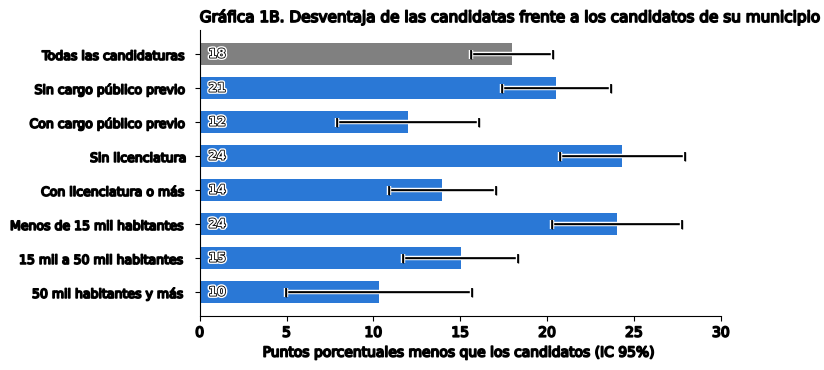

In [10]:
from pathlib import Path
import matplotlib.patheffects as pe
from matplotlib.text import Text
fig, ax = plt.subplots(figsize=(7.5, 3.8))
y = np.arange(len(panel_b))[::-1]
col = [GRIS] + [AZUL] * (len(panel_b) - 1)
ax.barh(y, panel_b.brecha, color=col, height=0.65)
intervalos = ax.errorbar(panel_b.brecha, y, xerr=[panel_b.brecha - panel_b.ic_inf, panel_b.ic_sup - panel_b.brecha], fmt='none', ecolor='black', capsize=3, lw=1)
for artista in (*intervalos.lines[1], *intervalos.lines[2]):
    artista.set_path_effects([pe.Stroke(linewidth=3.2, foreground='white'),
                              pe.Stroke(linewidth=1.2, foreground='black'), pe.Normal()])
for yi, v in zip(y, panel_b.brecha): ax.text(0.5, yi, r0(v), va='center', color='white', fontweight='bold', fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(panel_b.index, fontsize=9); ax.set_xlim(0, 30)
ax.set_xlabel('Puntos porcentuales menos que los candidatos (IC 95%)')
[ax.spines[k].set_visible(False) for k in ['top', 'right']]
ax.set_title('Gráfica 1B. Desventaja de las candidatas frente a los candidatos de su municipio', loc='left', fontsize=11)
plt.tight_layout()
fig.patch.set_alpha(0)
for ax in fig.axes:
    ax.patch.set_alpha(0)
for texto in fig.findobj(match=Text):
    texto.set_path_effects([pe.Stroke(linewidth=3.2, foreground='white'),
                            pe.Stroke(linewidth=1.2, foreground='black'), pe.Normal()])
figuras_dir = Path('docs/figuras') if Path('docs').is_dir() else Path('../docs/figuras')
figuras_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figuras_dir / 'grafica_1B_brechas.png', dpi=150, transparent=True, facecolor='none', edgecolor='none', bbox_inches='tight')
plt.show()

**¿Se mantienen las diferencias al considerarlas juntas?** Licenciatura, experiencia y tamaño del municipio están relacionados: en los municipios pequeños hay menos candidaturas con licenciatura. Por eso se estiman las tres interacciones en un solo modelo.

Además se prueba cada rasgo del perfil por separado, y luego todos los significativos a la vez. Así se ve qué rasgos cambian el tamaño de la brecha y cuáles no.

In [11]:
mj = mco('mujer*chico15 + mujer*lic_o_mas + mujer*tray_cargo_previo')
print('Interacciones estimadas juntas (con tamaño del municipio):')
print(pd.DataFrame({'coef': mj.params, 'p': mj.pvalues}).loc[['mujer:chico15', 'mujer:lic_o_mas', 'mujer:tray_cargo_previo']].round(3).to_string())

rasgos = ['edad_dec', 'lic_o_mas', 'tray_cargo_previo', 'plantilla_alguno', 'fb_personal', 'n_redes_personal', 'log_len_total',
          'indigena', 'fuerza21', 'partido_gobierna', 'cargo_2021_oficial', 'apellido_alcalde21']
una_a_una = pd.DataFrame({v: {'interacción': mco(f'mujer*{v}').params[f'mujer:{v}'], 'p': mco(f'mujer*{v}').pvalues[f'mujer:{v}']} for v in rasgos}).T
print('\nInteracción mujer x rasgo, una por una (positivo = la brecha se reduce):')
print(una_a_una.rename(index=ETIQ).round(3).to_string())

sig = ['edad_dec', 'lic_o_mas', 'tray_cargo_previo', 'log_len_total', 'indigena', 'cargo_2021_oficial']
mc_ = mco('mujer + ' + ' + '.join(sig) + ' + ' + ' + '.join(f'mujer:{v}' for v in sig))
print('\nTodas las interacciones significativas a la vez:')
print(pd.DataFrame({'coef': mc_.params, 'p': mc_.pvalues}).loc[[f'mujer:{v}' for v in sig]].round(3).to_string())

Interacciones estimadas juntas (con tamaño del municipio):
                          coef      p
mujer:chico15           -6.856  0.005
mujer:lic_o_mas          7.630  0.003
mujer:tray_cargo_previo  6.675  0.014



Interacción mujer x rasgo, una por una (positivo = la brecha se reduce):
                                                 interacción      p
Edad (por década)                                      3.305  0.005
Licenciatura o más                                    10.355  0.000
Declaró cargo público previo                           8.543  0.002
Ficha con texto repetido                              -5.292  0.208
Cuenta propia de Facebook                              1.683  0.505
Número de redes propias                                1.905  0.121
Extensión de la ficha (log)                            7.116  0.012
Autoadscripción indígena                              -6.452  0.012
Votación del partido en 2021 (puntos)                  0.026  0.774
El partido gobernaba el municipio                      2.127  0.557
Cargo en 2022-2025 (síndico, regidor, diputado)       21.198  0.002
Comparte apellido con el alcalde saliente             -5.002  0.205



Todas las interacciones significativas a la vez:
                            coef      p
mujer:edad_dec             2.914  0.015
mujer:lic_o_mas            8.507  0.001
mujer:tray_cargo_previo    5.243  0.057
mujer:log_len_total        4.133  0.137
mujer:indigena            -4.181  0.106
mujer:cargo_2021_oficial  15.426  0.018


Licenciatura, experiencia y tamaño del municipio mantienen su efecto al estimarse juntos. En el modelo con todos los rasgos del perfil, la experiencia declarada queda en el límite de la significancia, aunque sigue siendo clara en el modelo que incluye el tamaño del municipio. La extensión de la ficha y la autoadscripción indígena dejan de ser significativas al estimarse junto con los demás rasgos.

**Estimación por sexo.** Otra forma de verlo es estimar el modelo por separado para mujeres y para hombres. Entre las candidatas, haber ocupado un cargo suma unos siete puntos. Entre los candidatos no tiene un efecto que se distinga de cero.

**Cargo oficial en 2022-2025.** Para las pocas candidatas que fueron síndicas, regidoras o diputadas locales, la brecha desaparece en el punto estimado. Con tan pocos casos el intervalo es muy amplio, así que el dato no se usó en el documento.

In [12]:
for s, nombre in [(1, 'candidatas'), (0, 'candidatos')]:
    m = mco('tray_cargo_previo + plantilla_alguno', datos=cand[cand.mujer == s])
    print(f'Solo {nombre}: cargo previo {m.params["tray_cargo_previo"]:+.2f} (p={m.pvalues["tray_cargo_previo"]:.3f}), '
          f'texto repetido {m.params["plantilla_alguno"]:+.2f} (p={m.pvalues["plantilla_alguno"]:.3f})')
m = mco('mujer*plantilla_alguno'); print(f'¿La ficha repetida castiga más a las mujeres? interacción {m.params["mujer:plantilla_alguno"]:.2f}, p={m.pvalues["mujer:plantilla_alguno"]:.2f}')
m = mco('mujer*cargo_2021_oficial'); t = m.t_test('mujer + mujer:cargo_2021_oficial = 0')
print(f'Brecha entre quienes tuvieron cargo en 2022-2025: {float(t.effect[0]):+.1f} (IC {t.conf_int()[0][0]:.1f} a {t.conf_int()[0][1]:.1f}); '
      f'{int(cand[(cand.mujer==1)].cargo_2021_oficial.sum())} candidatas y {int(cand[(cand.mujer==0)].cargo_2021_oficial.sum())} candidatos')

Solo candidatas: cargo previo +7.06 (p=0.004), texto repetido -7.25 (p=0.006)
Solo candidatos: cargo previo +1.55 (p=0.521), texto repetido -2.81 (p=0.594)


¿La ficha repetida castiga más a las mujeres? interacción -5.29, p=0.21


Brecha entre quienes tuvieron cargo en 2022-2025: +2.6 (IC -10.3 a 15.6); 22 candidatas y 13 candidatos


## 8. El perfil de las candidatas

¿En qué se distinguen las candidatas de los candidatos? La columna "diferencia" es el coeficiente de `mujer` en una regresión de cada rasgo, con efectos fijos de municipio y partido, es decir, dentro de la misma elección.

In [13]:
rasgos_perfil = {'edad': 'Edad (años)', 'lic_o_mas': 'Licenciatura o más', 'indigena': 'Autoadscripción indígena',
                 'tray_cargo_previo': 'Declaró cargo público previo', 'plantilla_alguno': 'Ficha con texto repetido (cualquier campo)',
                 'propuestas_plantilla': 'Propuestas con texto repetido', 'n_redes_personal': 'Número de redes propias',
                 'cargo_2021_oficial': 'Cargo en 2022-2025', 'apellido_alcalde21': 'Comparte apellido con el alcalde saliente',
                 'tema_educacion': 'Propuestas: educación', 'tema_social_grupos': 'Propuestas: grupos vulnerables',
                 'tema_campo': 'Propuestas: campo', 'tema_agua_drenaje': 'Propuestas: agua y drenaje'}
perfil = []
for v, e in rasgos_perfil.items():
    m = mco('mujer', y=v)
    perfil.append({'rasgo': e, 'hombres': cand.loc[cand.mujer == 0, v].mean(), 'mujeres': cand.loc[cand.mujer == 1, v].mean(),
                   'diferencia (misma elección)': m.params['mujer'], 'p': m.pvalues['mujer']})
pd.DataFrame(perfil).set_index('rasgo').round(3)

,hombres,mujeres,diferencia (misma elección),p
rasgo,,,,
Edad (años),48.531,44.810,-2.882,0.000
Licenciatura o más,0.677,0.587,-0.056,0.084
Autoadscripción indígena,0.245,0.253,-0.005,0.782
Declaró cargo público previo,0.469,0.296,-0.161,0.000
Ficha con texto repetido (cualquier campo),0.047,0.112,0.064,0.000
Propuestas con texto repetido,0.032,0.097,0.060,0.000
Número de redes propias,0.715,0.536,-0.183,0.024
Cargo en 2022-2025,0.023,0.040,0.021,0.032
Comparte apellido con el alcalde saliente,0.125,0.106,-0.037,0.142


Las candidatas son casi tres años más jóvenes y declaran con menos frecuencia un cargo público previo. También tienen con más frecuencia fichas con texto repetido: en el campo de propuestas es el triple (10 contra 3 por ciento). No difieren en autoadscripción indígena. En escolaridad la diferencia es pequeña y solo marginalmente significativa.

**Apellidos.** El cruce de apellidos con el alcalde saliente se compara con un placebo: el alcalde de un municipio elegido al azar. La coincidencia real es unas tres veces la del placebo, en ambos sexos. Sin embargo, no prueba parentesco en casos individuales y no detecta a cónyuges.

In [14]:
ap = cand.groupby('mujer')[['apellido_alcalde21', 'apellido_placebo']].mean().mul(100).round(1)
ap.index = ['Hombres', 'Mujeres']; ap.columns = ['Alcalde de su municipio (%)', 'Alcalde de otro municipio al azar (%)']
print(f"Total: {100*cand.apellido_alcalde21.mean():.1f}% contra {100*cand.apellido_placebo.mean():.1f}% del placebo")
ap

Total: 11.6% contra 3.5% del placebo


,Alcalde de su municipio (%),Alcalde de otro municipio al azar (%)
Hombres,12.5,3.5
Mujeres,10.6,3.6


## 9. Relevancia de las propuestas frente a las carencias del municipio

**Pregunta.** ¿Ganan más votos las candidaturas cuyas propuestas atienden los problemas más graves de su municipio? ¿Explica eso la brecha?

**Construcción.** Para cinco temas de propuesta hay un indicador del Censo 2020 que mide la carencia correspondiente:

| Tema de la propuesta | Carencia del municipio (Censo 2020) |
|---|---|
| Agua y drenaje | Viviendas sin agua entubada y viviendas sin drenaje (promedio de sus percentiles) |
| Salud | Población sin afiliación a servicios de salud |
| Educación | Analfabetismo (15 años y más) |
| Economía y empleo | Desocupación |
| Campo | Población en secciones rurales |

Cada carencia se convierte en un percentil estatal (0 a 1). Una propuesta es **relevante** si menciona el tema y el municipio está en el tercio más rezagado del estado en esa carencia. La **principal carencia** de cada municipio es aquella en la que ocupa el percentil más alto. Seguridad no se evaluó porque la base no tiene datos municipales de delitos.

In [15]:
TEMAS = {'agua_drenaje': ['sin_agua', 'sin_drenaje'], 'salud': ['sin_servsalud'], 'educacion': ['analfab'],
         'economia_empleo': ['desocup'], 'campo': ['pct_rural']}
pct = mun.rank(pct=True)
nec = pd.DataFrame(index=mun.index)
for t, vs in TEMAS.items():
    nec['need_' + t] = pct[vs].mean(axis=1).rank(pct=True)
    nec['alta_' + t] = (nec['need_' + t] >= 2/3).astype(int)
nec['principal'] = nec[[f'need_{t}' for t in TEMAS]].idxmax(axis=1).str.replace('need_', '')
print('Principal carencia de cada municipio:', nec.principal.value_counts().to_dict())
print('\nCarencias municipales (promedio simple entre municipios):'); print(mun[['sin_agua', 'sin_drenaje', 'sin_servsalud', 'analfab', 'desocup', 'pct_rural']].mean().round(1).to_string())

c9 = cand.merge(nec, left_on='ID_MUNICIPIO', right_index=True, how='left')
for t in TEMAS: c9['rel_' + t] = c9['tema_' + t] * c9['alta_' + t]
c9['relevante'] = (c9[[f'rel_{t}' for t in TEMAS]].sum(axis=1) > 0).astype(int)
c9['n_rel'] = c9[[f'rel_{t}' for t in TEMAS]].sum(axis=1)
c9['menciona_principal'] = [r['tema_' + r.principal] for _, r in c9.iterrows()]
c9['n_temas5'] = c9[[f'tema_{t}' for t in TEMAS]].sum(axis=1)
print('\n% con al menos una propuesta relevante:', (100 * c9.groupby('mujer').relevante.mean()).round(1).rename({0: 'hombres', 1: 'mujeres'}).to_dict())
m = mco('mujer + n_temas5', y='relevante', datos=c9)
print(f'Diferencia mujeres-hombres dentro de la misma elección: {m.params["mujer"]:+.3f} (p={m.pvalues["mujer"]:.2f})')

Principal carencia de cada municipio: {'salud': 57, 'economia_empleo': 53, 'campo': 37, 'agua_drenaje': 33, 'educacion': 32}

Carencias municipales (promedio simple entre municipios):
sin_agua         10.7
sin_drenaje      14.7
sin_servsalud    25.8
analfab          12.5
desocup           2.1
pct_rural        45.6

% con al menos una propuesta relevante: {'hombres': 50.7, 'mujeres': 58.8}
Diferencia mujeres-hombres dentro de la misma elección: +0.018 (p=0.56)


**¿Las propuestas siguen las carencias?** Si fuera así, un tema se mencionaría mucho más donde la carencia es mayor. La tabla compara el porcentaje de candidaturas que mencionan cada tema en los municipios más rezagados y en el resto.

In [16]:
resp = pd.DataFrame({t: {'Menciona donde la carencia es alta (%)': 100 * c9.loc[c9['alta_' + t] == 1, 'tema_' + t].mean(),
                         'Menciona en el resto (%)': 100 * c9.loc[c9['alta_' + t] == 0, 'tema_' + t].mean(),
                         'Candidaturas en municipios con carencia alta': int((c9['alta_' + t] == 1).sum())} for t in TEMAS}).T
resp.round(1)

,Menciona donde la carencia es alta (%),Menciona en el resto (%),Candidaturas en municipios con carencia alta
agua_drenaje,48.4,41.8,380.0
salud,42.9,41.5,371.0
educacion,38.7,34.2,377.0
economia_empleo,49.9,57.3,373.0
campo,26.6,24.9,372.0


**¿Hacer propuestas relevantes da votos?** Todas las especificaciones usan los mismos controles del modelo completo (perfil y antecedentes), además de los efectos fijos de municipio y partido. En la mayoría se incluye también la mención de cada tema, para separar el efecto de "hablar de agua" del de "hablar de agua donde falta agua".

In [17]:
MEN = ' + '.join(f'tema_{t}' for t in TEMAS); BASE = PERFIL + ' + ' + ANTECEDENTES
for t in TEMAS: c9[f'relm_{t}'] = c9[f'tema_{t}'] * (c9[f'need_{t}'] >= 0.5)
c9['relevante_mediana'] = (c9[[f'relm_{t}' for t in TEMAS]].sum(axis=1) > 0).astype(int)
c9['indice_ajuste'] = sum(c9[f'tema_{t}'] * c9[f'need_{t}'] for t in TEMAS)
especs = [('Al menos una relevante (con número de temas)', f'mujer + relevante + n_temas5 + {BASE}', 'relevante', c9),
          ('Al menos una relevante (con menciones de cada tema)', f'mujer + relevante + {MEN} + {BASE}', 'relevante', c9),
          ('Relevante x mujer', f'mujer*relevante + {MEN} + {BASE}', 'mujer:relevante', c9),
          ('Menciona la principal carencia', f'mujer + menciona_principal + {MEN} + {BASE}', 'menciona_principal', c9),
          ('Número de propuestas relevantes', f'mujer + n_rel + {MEN} + {BASE}', 'n_rel', c9),
          ('Umbral en la mediana', f'mujer + relevante_mediana + {MEN} + {BASE}', 'relevante_mediana', c9),
          ('Índice continuo (mención x percentil de carencia)', f'mujer + indice_ajuste + {MEN} + {BASE}', 'indice_ajuste', c9),
          ('Solo fichas sin texto repetido', f'mujer + relevante + {MEN} + ' + BASE.replace('plantilla_alguno + ', ''), 'relevante', c9[c9.plantilla_alguno == 0])]
res = []
for nombre, f, v, d in especs:
    m = mco(f, datos=d); res.append({'especificación': nombre, 'coeficiente': m.params[v], 'p': m.pvalues[v], 'N': int(m.nobs)})
m = mco(f'mujer + relevante + {MEN} + {BASE}', y='gano', datos=c9)
res.append({'especificación': 'Probabilidad de ganar', 'coeficiente': m.params['relevante'], 'p': m.pvalues['relevante'], 'N': int(m.nobs)})
b_con = mco(f'mujer + relevante + {MEN} + {BASE}', datos=c9).params['mujer']
print(f'Brecha con y sin relevancia: {M["+ antecedentes políticos"].params["mujer"]:.2f} -> {b_con:.2f}')
pd.DataFrame(res).set_index('especificación').round(3)

Brecha con y sin relevancia: -16.16 -> -16.31


,coeficiente,p,N
especificación,,,
Al menos una relevante (con número de temas),1.293,0.390,1093
Al menos una relevante (con menciones de cada tema),1.242,0.409,1093
Relevante x mujer,-2.947,0.216,1093
Menciona la principal carencia,2.104,0.125,1093
Número de propuestas relevantes,2.071,0.088,1093
Umbral en la mediana,0.155,0.928,1093
Índice continuo (mención x percentil de carencia),2.396,0.239,1093
Solo fichas sin texto repetido,1.649,0.304,1005
Probabilidad de ganar,0.027,0.511,1093


Ninguna especificación muestra un efecto robusto de la relevancia sobre el voto, ni para mujeres ni para hombres, y la brecha no cambia al incluirla.

Hay dos límites que conviene tener presentes:

- **El tema se detecta por palabras clave.** Mencionar "agua" no garantiza una propuesta concreta. Se intentó medir qué tan concretas son las propuestas con un índice por reglas, pero no pasó la validación contra etiquetas hechas a mano (63 por ciento de acierto en una muestra ciega, kappa de 0.25), así que no se usó.
- **Las carencias son de 2020.**

## 10. Dónde se postula a las mujeres

**Tamaño del municipio.** Las mujeres son la mayoría de las candidaturas en los municipios pequeños y una minoría en los grandes.

**Municipios que el partido ya gobernaba.** Ahí se postulan menos mujeres. Esas candidaturas son las que más ganan, y en ellas los hombres son mayoría.

**Fuerza del partido.** Para cada partido, los municipios se ordenan según el porcentaje de votos que obtuvo en 2021 (hubiera ganado o no) y se dividen en tercios: fuerza débil, media y fuerte. La fuerza es relativa a cada partido. Un municipio "fuerte" para Morena-PVEM es donde obtuvo más de 40 por ciento, y para el PT basta con más de 3 por ciento. Es una aproximación a los bloques de competitividad del OPLE, cuyo cálculo oficial puede diferir.

In [18]:
tam = cand.groupby('tam', observed=True).agg(municipios=('ID_MUNICIPIO', 'nunique'), candidaturas=('mujer', 'size'),
                                             pct_mujeres=('mujer', 'mean'), alcaldesas=('gano', lambda s: int((s * cand.loc[s.index, 'mujer']).sum())))
tam['pct_mujeres'] = (100 * tam.pct_mujeres).round(1)
print('Por tamaño del municipio:'); print(tam.to_string())

d = cand[cand.fuerza21.notna() & (cand.partido != 'CI')].copy()
mg = smf.ols('mujer ~ partido_gobierna + C(partido)', d).fit(cov_type='cluster', cov_kwds={'groups': d.ID_MUNICIPIO})
print(f'\nDonde el partido gobernaba, la probabilidad de postular mujer cambia {100*mg.params["partido_gobierna"]:+.1f} puntos (p={mg.pvalues["partido_gobierna"]:.3f})')
g = cand[cand.partido_gobierna == 1]
print(f'Candidaturas del partido que gobernaba: ganaron {100*g.gano.mean():.1f}% contra {100*cand[cand.partido_gobierna==0].gano.mean():.1f}% del resto')
print(f'En ese grupo, hombres: {100*(g.mujer==0).mean():.1f}% de las candidaturas (resto {100*(cand[cand.partido_gobierna==0].mujer==0).mean():.1f}%) '
      f'y {100*(g[g.gano==1].mujer==0).mean():.1f}% de quienes ganaron ({int((g[g.gano==1].mujer==0).sum())} de {int(g.gano.sum())})')

d['fuerza'] = d.groupby('partido').fuerza21.transform(lambda s: pd.qcut(s.rank(method='first'), 3, labels=['Débil', 'Media', 'Fuerte']))
corte = d.groupby(['partido', 'fuerza'], observed=True).fuerza21.min().unstack()[['Media', 'Fuerte']].round(1)
print('\nUmbral de votación 2021 (%) a partir del cual un municipio es de fuerza media o fuerte, por partido:'); print(corte.to_string())
bloques = pd.DataFrame({'% mujeres entre candidaturas': 100 * d.groupby('fuerza', observed=True).mujer.mean(),
                        '% candidatas que ganaron': 100 * d[d.mujer == 1].groupby('fuerza', observed=True).gano.mean(),
                        '% candidatos que ganaron': 100 * d[d.mujer == 0].groupby('fuerza', observed=True).gano.mean(),
                        'candidaturas': d.groupby('fuerza', observed=True).size()}).round(1)
print('\nGráfica 2 (datos):'); bloques

Por tamaño del municipio:
                            municipios  candidaturas  pct_mujeres  alcaldesas
tam                                                                          
Menos de 15 mil habitantes          78           409         57.9          22
15 mil a 50 mil habitantes          94           492         49.4          25
50 mil habitantes y más             40           207         35.7           7

Donde el partido gobernaba, la probabilidad de postular mujer cambia -9.1 puntos (p=0.035)
Candidaturas del partido que gobernaba: ganaron 40.9% contra 15.3% del resto
En ese grupo, hombres: 56.7% de las candidaturas (resto 48.8%) y 68.7% de quienes ganaron (46 de 67)

Umbral de votación 2021 (%) a partir del cual un municipio es de fuerza media o fuerte, por partido:
fuerza    Media  Fuerte
partido                
MC          1.2    10.7
MOR         6.4    16.2
MOR_PVEM   21.2    39.5
PAN         3.2    17.0
PRI         2.2    10.7
PT          0.9     2.6
PVEM        1.5    1

,% mujeres entre candidaturas,% candidatas que ganaron,% candidatos que ganaron,candidaturas
fuerza,,,,
Débil,54.8,7.0,24.1,367
Media,50.6,4.9,24.0,362
Fuerte,46.2,18.5,37.2,364


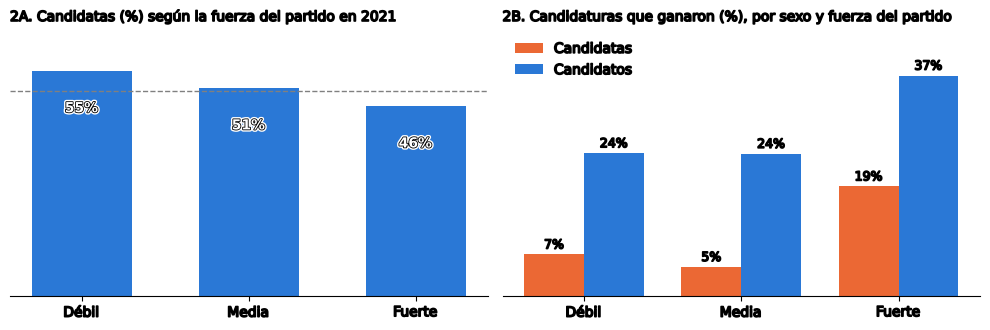

In [19]:
from pathlib import Path
import matplotlib.patheffects as pe
from matplotlib.text import Text
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
x = np.arange(3)
a1.bar(x, bloques['% mujeres entre candidaturas'], color=AZUL, width=0.6)
a1.axhline(50, color=GRIS, ls='--', lw=1)
for xi, v in zip(x, bloques['% mujeres entre candidaturas']): a1.text(xi, v - 10, r0(v) + '%', ha='center', color='white', fontweight='bold')
a1.set_xticks(x); a1.set_xticklabels(bloques.index); a1.set_ylim(0, 65); a1.set_yticks([])
a1.set_title('2A. Candidatas (%) según la fuerza del partido en 2021', loc='left', fontsize=10)
w = 0.38
a2.bar(x - w/2, bloques['% candidatas que ganaron'], w, color=NARANJA, label='Candidatas')
a2.bar(x + w/2, bloques['% candidatos que ganaron'], w, color=AZUL, label='Candidatos')
for xi, (vm, vh) in enumerate(zip(bloques['% candidatas que ganaron'], bloques['% candidatos que ganaron'])):
    a2.text(xi - w/2, vm + 1, r0(vm) + '%', ha='center', fontsize=9); a2.text(xi + w/2, vh + 1, r0(vh) + '%', ha='center', fontsize=9)
a2.set_xticks(x); a2.set_xticklabels(bloques.index); a2.set_ylim(0, 45); a2.set_yticks([]); a2.legend(frameon=False, loc='upper left')
a2.set_title('2B. Candidaturas que ganaron (%), por sexo y fuerza del partido', loc='left', fontsize=10)
for a in (a1, a2): [a.spines[k].set_visible(False) for k in ['top', 'right', 'left']]
plt.tight_layout()
fig.patch.set_alpha(0)
for ax in fig.axes:
    ax.patch.set_alpha(0)
for texto in fig.findobj(match=Text):
    texto.set_path_effects([pe.Stroke(linewidth=3.2, foreground='white'),
                            pe.Stroke(linewidth=1.2, foreground='black'), pe.Normal()])
figuras_dir = Path('docs/figuras') if Path('docs').is_dir() else Path('../docs/figuras')
figuras_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figuras_dir / 'grafica_2_fuerza_partido.png', dpi=150, transparent=True, facecolor='none', edgecolor='none', bbox_inches='tight')
plt.show()

Los partidos postulan algo más de mujeres donde son débiles, pero la colocación no explica la brecha. Aun donde el partido era fuerte, las candidatas ganaron la mitad de veces que los candidatos, y la brecha de votos se mantiene al comparar con candidatos cuyo partido tenía la misma fuerza en el municipio. Lo confirma el modelo de la sección 5: `fuerza21` entra como control en el modelo completo y la interacción con `mujer`, en la sección 7, no es significativa.

## 11. Análisis que quedaron fuera

- **Nivel seccional.** Se estimó un panel de candidatura por sección electoral (24,892 observaciones) con efectos fijos de candidatura y de sección, para ver si la desventaja cambia según la composición de cada sección. La razón de sexos, la jefatura femenina de hogar y la participación económica femenina no la mueven de forma robusta; solo se atenúa levemente en las secciones más marginadas. No se incluyó en el documento por espacio y porque no cambia la conclusión. Los datos seccionales no acompañan a este cuaderno.
- **Coalición Morena-PVEM.** La brecha es menor donde Morena compitió en coalición (unos 15 puntos) que donde fue sola (28). Pero los municipios donde fue sola son más pequeños, rurales y marginados, y ahí el partido ya era débil, así que la diferencia no se puede atribuir a la coalición. En 2025 fue la única coalición registrada en ayuntamientos.
- **Temas de las propuestas.** Estimando los once temas a la vez con efectos fijos, solo uno resulta significativo al 5 por ciento, lo esperable por azar al probar once.
- **Reelección.** Ninguna candidatura de 2025 corresponde a quien ganó la presidencia en 2021. Los periodos de cuatro años en Veracruz impiden la reelección consecutiva.

In [20]:
temas11 = [c for c in cand.columns if c.startswith('tema_')]
mt = mco(' + '.join(temas11))
tt = pd.DataFrame({'coef': mt.params, 'p': mt.pvalues}).loc[temas11].round(3)
print(f'Temas con p < 0.05: {(tt.p < 0.05).sum()} de {len(temas11)}'); tt

Temas con p < 0.05: 1 de 11


,coef,p
tema_seguridad,1.145,0.472
tema_agua_drenaje,0.560,0.693
tema_vialidades_obra,1.485,0.301
tema_salud,1.095,0.433
tema_educacion,-0.435,0.797
tema_economia_empleo,-1.879,0.193
tema_campo,3.103,0.047
tema_transparencia,-0.000,1.000
tema_social_grupos,-1.246,0.411
tema_medio_ambiente,-0.902,0.591


## 12. Limitaciones

El análisis es observacional: describe diferencias dentro de cada elección, no efectos causales. Los efectos fijos descuentan todo lo que comparten las candidaturas de un municipio. No descuentan lo que distingue a cada campaña y no se observa: gasto, estructura territorial, apoyo del partido o cobertura en medios. Por eso no se puede separar si la brecha viene del electorado, de los partidos o de los recursos de campaña.

Hay otras cuatro limitaciones:

- **Las variables de perfil dependen de lo que cada candidatura declaró en Conóceles,** y la calidad de las fichas es desigual. La ficha con texto repetido es, en sí misma, un indicador de ese problema.
- **Los bloques de fuerza son una aproximación,** no el cálculo oficial del OPLE.
- **Tamiahua usa resultados del PREP,** no del cómputo.
- **El análisis no identifica el comportamiento de votantes individuales.**

## 13. Trazabilidad de las cifras del documento

La tabla compara cada cifra citada en el documento con el valor que calcula este cuaderno. Las cifras que no vienen de estas bases (por ejemplo, diputaciones de 2024 o datos nacionales) se indican como externas.

In [21]:
bl = bloques
traz = [
 ('Mujeres, % de candidaturas', 50, pct_cand), ('Mujeres, % de votos', 30, pct_votos), ('Alcaldesas 2025', 54, n_alc),
 ('Alcaldesas 2025, %', 25, 100*n_alc/n_mun), ('Alcaldesas 2021, %', 24, pres21), ('Diputaciones de mayoría 2021, %', 40, dip21),
 ('Votación promedio candidatas, %', 12, cand[cand.mujer==1].share100.mean()), ('Votación promedio candidatos, %', 26, cand[cand.mujer==0].share100.mean()),
 ('Sindicaturas de mujeres 2025, %', 76, sind25), ('Regidurías de mujeres 2021, %', 46, reg21), ('Regidurías de mujeres 2025, %', 72, reg25),
 ('Primer lugar de listas de regidurías 2021, %', 43, r1_21), ('Primer lugar de listas de regidurías 2025, %', 91, r1_25),
 ('Sindicatura de sexo distinto (de 211)', 208, n_sind_distinto),
 ('Brecha sin controles (puntos)', 14, -b_sin), ('Brecha misma elección (puntos)', 18, -b_fe), ('Brecha perfil equivalente (puntos)', 16, -b_ant),
 ('Votos menos por cada cien electores', 11.7, -efecto(mco('mujer', y='votos_ln')).coef), ('Menor probabilidad de ganar (puntos)', 25, -100*efecto(mco('mujer', y='gano')).coef),
 ('Brecha sin cargo previo', 21, panel_b.loc['Sin cargo público previo', 'brecha']), ('Brecha con cargo previo', 12, panel_b.loc['Con cargo público previo', 'brecha']),
 ('Brecha sin licenciatura', 24, panel_b.loc['Sin licenciatura', 'brecha']), ('Brecha con licenciatura', 14, panel_b.loc['Con licenciatura o más', 'brecha']),
 ('Brecha, menos de 15 mil hab.', 24, panel_b.loc['Menos de 15 mil habitantes', 'brecha']), ('Brecha, 15 a 50 mil hab.', 15, panel_b.loc['15 mil a 50 mil habitantes', 'brecha']),
 ('Brecha, 50 mil hab. y más', 10, panel_b.loc['50 mil habitantes y más', 'brecha']),
 ('Cargo previo suma a una candidata (puntos)', 7, mco('tray_cargo_previo + plantilla_alguno', datos=cand[cand.mujer == 1]).params['tray_cargo_previo']),
 ('Candidatas: diferencia de edad (años)', -3, mco('mujer', y='edad').params['mujer']),
 ('Declaró cargo previo, candidatas %', 30, 100*cand[cand.mujer==1].tray_cargo_previo.mean()), ('Declaró cargo previo, candidatos %', 47, 100*cand[cand.mujer==0].tray_cargo_previo.mean()),
 ('Propuestas con texto repetido, candidatas %', 10, 100*cand[cand.mujer==1].propuestas_plantilla.mean()), ('Propuestas con texto repetido, candidatos %', 3, 100*cand[cand.mujer==0].propuestas_plantilla.mean()),
 ('Hablan de agua donde la carencia es alta, %', 48, resp.iloc[0, 0]), ('Hablan de agua en el resto, %', 42, resp.iloc[0, 1]),
 ('Efecto de propuesta relevante (puntos)', 1.2, res[1]['coeficiente']),
 ('Candidatas en municipios de menos de 15 mil, %', 58, tam.iloc[0]['pct_mujeres']), ('Candidatas en municipios de 50 mil y más, %', 36, tam.iloc[2]['pct_mujeres']),
 ('Menos mujeres donde el partido gobernaba (puntos)', 9, -100*mg.params['partido_gobierna']),
 ('Partido que gobernaba: ganaron %', 41, 100*g.gano.mean()), ('Resto: ganaron %', 15, 100*cand[cand.partido_gobierna==0].gano.mean()),
 ('Partido que gobernaba: hombres % de candidaturas', 57, 100*(g.mujer==0).mean()), ('Partido que gobernaba: hombres % de ganadores', 69, 100*(g[g.gano==1].mujer==0).mean()),
 ('Candidatas, fuerza débil %', 55, bl.iloc[0, 0]), ('Candidatas, fuerza media %', 51, bl.iloc[1, 0]), ('Candidatas, fuerza fuerte %', 46, bl.iloc[2, 0]),
 ('Ganaron donde el partido es fuerte: candidatas %', 19, bl.iloc[2, 1]), ('Ganaron donde el partido es fuerte: candidatos %', 37, bl.iloc[2, 2]),
 ('Apellido compartido con alcalde saliente, %', 11.6, 100*cand.apellido_alcalde21.mean()), ('Apellido, placebo %', 3.5, 100*cand.apellido_placebo.mean()),
]
T = pd.DataFrame(traz, columns=['Cifra del documento', 'Documento', 'Calculado'])
T['Calculado'] = T.Calculado.astype(float).round(1)
tol = np.where(T.Documento == T.Documento.round(0), 0.51, 0.051)   # cifras enteras en el texto admiten redondeo
T['Coincide'] = np.where((T.Calculado - T.Documento).abs() <= tol, 'sí', 'revisar')
print('Cifras externas (no calculables con estas bases): diputaciones de mayoría 2024 (16 de 30, prensa); presidencias municipales en el país 2010-2024 (INE/INMUJERES); 41% de alcaldesas con parentesco (Mendoza Madrigal, 2024).')
print(f"Coinciden {(T.Coincide == 'sí').sum()} de {len(T)}")
T

Cifras externas (no calculables con estas bases): diputaciones de mayoría 2024 (16 de 30, prensa); presidencias municipales en el país 2010-2024 (INE/INMUJERES); 41% de alcaldesas con parentesco (Mendoza Madrigal, 2024).
Coinciden 49 de 49


,Cifra del documento,Documento,Calculado,Coincide
0,"Mujeres, % de candidaturas",50.0,50.0,sí
1,"Mujeres, % de votos",30.0,30.5,sí
2,Alcaldesas 2025,54.0,54.0,sí
3,"Alcaldesas 2025, %",25.0,25.5,sí
4,"Alcaldesas 2021, %",24.0,24.0,sí
5,"Diputaciones de mayoría 2021, %",40.0,40.0,sí
6,"Votación promedio candidatas, %",12.0,12.2,sí
7,"Votación promedio candidatos, %",26.0,26.0,sí
8,"Sindicaturas de mujeres 2025, %",76.0,76.3,sí
9,"Regidurías de mujeres 2021, %",46.0,45.7,sí


## Referencias

- **Datos:**
  - INE: Conóceles, SICEE (cómputos e integración de ayuntamientos 2021 y 2025).
  - OPLE Veracruz: PREP de la elección extraordinaria de Tamiahua 2026; oficios OPLEV/DEOE/0587/2026 y 0677/2026.
  - INEGI: Censo de Población y Vivienda 2020 por sección electoral.
- **Normativa:**
  - Código Electoral para el Estado de Veracruz, art. 16.
  - Acuerdos del INE INE/CG591/2023 e INE/CG55/2025.
  - Reforma a la Constitución de Veracruz del 30 de junio de 2026.
- **Organismos internacionales:** Comité CEDAW, *Observaciones finales sobre el décimo informe periódico de México* (CEDAW/C/MEX/CO/10), julio de 2025.
- **Literatura:**
  - Mendoza Madrigal, M. (2024). *El parentesco como puerta de entrada de las mujeres a los gobiernos locales. Caso las alcaldesas veracruzanas*. TEPJF.
  - Thomas, M. y Bodet, M. A. (2013). Sacrificial lambs, women candidates, and district competitiveness in Canada. *Electoral Studies*, 32(1).